<a href="https://colab.research.google.com/github/Saku53/Telecom_Pathfinding/blob/main/telecom_pathfinding_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pathfinding on the SNAP Telecom Graph: A* vs ALT vs Hill Climbing

**Task.** Given two nodes in the telecom graph (users, packages, apps, cells), find a low-cost chain of relationships connecting them.

| Role | Algorithm | Type |
|---|---|---|
| From the syllabus | **A\*** (Informed Search, Week 3) | complete, optimal (admissible h) |
| Outside the syllabus | **ALT** = A\* + **L**andmarks + **T**riangle inequality (Goldberg & Harrelson, 2005), and **ALT+** = ALT combined with the unit bound (`max` of both heuristics) | complete, optimal |
| Required by the instructor | **Hill Climbing** (steepest-ascent, + sideways moves, + random restarts) | local search: incomplete, not optimal |

**How to use:** `Runtime > Run all`. Each algorithm lives in its own section, so you can re-run or copy one section into your report without touching the others. All tables go to `/content/results/*.csv` and all figures to `/content/results/*.png` (300 dpi, poster-ready).

> **Important.** The loader *auto-detects* the layout (first two columns = source/target ID, remaining columns = attributes in [0,1]). Node IDs in the SNAP files are **local to each node type**, so the loader gives each type its own ID range (the file names `edge_<src>_<verb>_<dst>` tell it the types). Section 2 prints what it found: the node-ID counts per type should add up to about 170K.

### Assignment checklist: where each requirement is covered

| Requirement | Where in this notebook |
|---|---|
| Algorithms assigned to the dataset (one from the syllabus + one outside + hill climbing) | Sections 4 (A\*), 5 and 5b (ALT, ALT+), 6 (Hill Climbing, 3 variants) |
| Data processing | Section 2 (loading, node-ID fix, costs, largest component) and Section 9a (data-processing summary table) |
| Results | Section 7 (summary table), Section 8 (outcome matrix and figures), Section 10 (search trees) |
| Accuracy score | Section 9a (accuracy = optimal-path rate, success rate, 95% confidence interval) |
| Time taken to finish the run | Section 9a (time per stage, time per algorithm, time per query, total notebook time) |
| Correctness check | Section 7 (A\*, ALT, ALT+ asserted equal to SciPy's Dijkstra on every query) |
| Statistical comparison | Section 9 (paired Wilcoxon tests) |

## 1. Setup and configuration

In [ ]:
import os, glob, time, heapq, tarfile, subprocess, tracemalloc, warnings
import numpy as np, pandas as pd
import scipy.sparse as sp
from scipy.sparse.csgraph import dijkstra, connected_components
import matplotlib.pyplot as plt
import networkx as nx
warnings.filterwarnings("ignore")

# ===================== CONFIG (edit here) =====================
DATA_URL   = "https://snap.stanford.edu/data/telecom-graph/telecom-graph.tar.gz"
DATA_DIR   = "/content/telecom"
OUT_DIR    = "/content/results"
MAX_ROWS_PER_EDGE_FILE = 1_500_000   # rows read from each edge_* file. None = all (50M edges total, needs a lot of RAM)
EDGE_WEIGHT_COL = None               # None = mean of all attribute columns; or an int (0 = first attribute column)
N_QUERIES    = 100                   # random (start, goal) pairs
QUERY_TYPE   = "user"                # sample start/goal among nodes of this type ("user" = how related are two users?). None = any node
N_LANDMARKS  = 16                    # for ALT
HC_SIDEWAYS  = 20                    # sideways moves allowed in hill-climbing variant 2
HC_RESTARTS  = 30                    # restarts in hill-climbing variant 3
N_MEM_QUERIES = 10                   # queries used for the memory measurement
SEED = 42
USE_SYNTHETIC_IF_DOWNLOAD_FAILS = True   # lets you test the notebook without the real data
# ==============================================================
os.makedirs(OUT_DIR, exist_ok=True)
rng_global = np.random.default_rng(SEED)
RUN_START = time.perf_counter()      # wall-clock start of the whole notebook
STAGE = {}                            # seconds spent in each stage (filled in below)
print("Setup done.")

Setup done.


## 2. Dataset loading and preprocessing

**State-space representation (for Report §2/§3):**
- **State** = a node of the graph (user, package, app or cell).
- **Actions** = traverse an edge to a neighbouring node.
- **Cost** of an edge = `1 + (1 - attribute)`, so a *stronger* relationship (attribute near 1) is *cheaper*; every cost lies in [1, 2].
- **Goal test** = current node equals the target node.
- Edges are treated as **bidirectional**: the data is directed (user -> app, user -> cell), but a user-to-user connection can only exist by going *user -> app -> (back) user*.
- Only the **largest connected component** is kept, so every query has a solution (this makes *completeness* testable).

In [ ]:
def download_data():
    os.makedirs(DATA_DIR, exist_ok=True)
    found = sorted(glob.glob(os.path.join(DATA_DIR, "**", "edge_*"), recursive=True))
    if found: return found
    tgz = os.path.join(DATA_DIR, "telecom-graph.tar.gz")
    rc = subprocess.call(["wget", "-q", "-O", tgz, DATA_URL])
    if rc == 0 and os.path.exists(tgz) and os.path.getsize(tgz) > 0:
        with tarfile.open(tgz) as tf: tf.extractall(DATA_DIR)
    return sorted(glob.glob(os.path.join(DATA_DIR, "**", "edge_*"), recursive=True))

def make_synthetic(dirpath, U=4000, P=15, A=300, C=200, seed=0):
    # tiny stand-in with the SAME layout as the real data: file names edge_<src>_<verb>_<dst>.txt and node IDs LOCAL to each type
    r = np.random.default_rng(seed); os.makedirs(dirpath, exist_ok=True)
    users = np.arange(U)
    pd.DataFrame({"s": users, "d": r.integers(0, P, U), "w": r.random(U)}).to_csv(f"{dirpath}/edge_user_buy_package.txt", index=False, header=False)
    pop = 1/np.arange(1, A+1)**0.8; pop /= pop.sum(); sr = np.repeat(users, 8)
    pd.DataFrame({"s": sr, "d": r.choice(A, len(sr), p=pop), "w": r.random(len(sr))}).to_csv(f"{dirpath}/edge_user_use_app.txt", index=False, header=False)
    sr = np.repeat(users, 2); base = (sr // (U//C)) + r.integers(0, 3, len(sr))
    pd.DataFrame({"s": sr, "d": base % C, "w": r.random(len(sr))}).to_csv(f"{dirpath}/edge_user_live_cell.txt", index=False, header=False)
    return sorted(glob.glob(f"{dirpath}/edge_*"))

def read_edge_file(path, nrows):
    # Layout assumption: col0 = source ID, col1 = target ID, remaining cols = attributes in [0,1]. Header auto-detected.
    with open(path) as f: first = f.readline().strip()
    try: [float(t) for t in first.split(",")]; header = None
    except ValueError: header = 0
    df = pd.read_csv(path, header=header, nrows=nrows)
    src = df.iloc[:, 0].to_numpy().astype(np.int64)
    dst = df.iloc[:, 1].to_numpy().astype(np.int64)
    attrs = df.iloc[:, 2:].apply(pd.to_numeric, errors="coerce")
    if attrs.shape[1] == 0: w = np.full(len(df), 0.5)
    elif EDGE_WEIGHT_COL is not None: w = attrs.iloc[:, EDGE_WEIGHT_COL].fillna(0.5).to_numpy()
    else: w = attrs.mean(axis=1).fillna(0.5).to_numpy()
    return src, dst, np.clip(w, 0, 1)

_t0 = time.perf_counter()
files = download_data()
if not files and USE_SYNTHETIC_IF_DOWNLOAD_FAILS:
    print("!! Real dataset not available here -> using a SYNTHETIC stand-in (numbers are NOT for your report).")
    files = make_synthetic("/content/synthetic")
USING_SYNTHETIC = any("synthetic" in f for f in files)

def edge_types(path):
    tok = os.path.splitext(os.path.basename(path))[0].split("_")          # edge_user_buy_package -> user ... package
    return (tok[1], tok[-1]) if len(tok) >= 3 else ("node", "node")

parts = []
for f in files:
    s_, d_, w_ = read_edge_file(f, MAX_ROWS_PER_EDGE_FILE); st, dt = edge_types(f)
    print(f"{os.path.basename(f):32s} {st:>5s}->{dt:<8s} rows={len(s_):>10,}  src[{s_.min()}..{s_.max()}]  dst[{d_.min()}..{d_.max()}]  attr mean={w_.mean():.3f}")
    parts.append(dict(src=s_, dst=d_, w=w_, st=st, dt=dt))

# !! Node IDs in the SNAP files are LOCAL to each node type (users 0..99999, apps 0..999, ...), so IDs of different types COLLIDE.
# Give every node type its own ID range so a user, an app and a cell with the same local ID stay different nodes.
type_size = {}
for p_ in parts:
    type_size[p_["st"]] = max(type_size.get(p_["st"], 0), int(p_["src"].max()) + 1)
    type_size[p_["dt"]] = max(type_size.get(p_["dt"], 0), int(p_["dst"].max()) + 1)
type_order = list(type_size); offset = {}; run_ = 0
for tn in type_order: offset[tn] = run_; run_ += type_size[tn]
for p_ in parts: p_["src"] = p_["src"] + offset[p_["st"]]; p_["dst"] = p_["dst"] + offset[p_["dt"]]
type_bounds = np.array([offset[tn] for tn in type_order])
print("\nNode IDs seen per type:", {k: f"{v:,}" for k, v in type_size.items()}, "| total:", f"{run_:,}")
STAGE["1. Download + read edge files"] = time.perf_counter() - _t0
print(f"[time] data loading: {STAGE['1. Download + read edge files']:.1f} s")

edge_user_buy_package.txt         user->package  rows= 1,500,000  src[0..99999]  dst[0..379]  attr mean=0.500
edge_user_live_cell.txt           user->cell     rows= 1,500,000  src[0..99999]  dst[0..68999]  attr mean=0.500
edge_user_use_app.txt             user->app      rows= 1,500,000  src[0..99999]  dst[0..999]  attr mean=0.500

Node IDs seen per type: {'user': '100,000', 'package': '380', 'cell': '69,000', 'app': '1,000'} | total: 170,380
[time] data loading: 605.3 s


In [ ]:
class Graph: pass

def build_graph(parts):
    src = np.concatenate([p_["src"] for p_ in parts]); dst = np.concatenate([p_["dst"] for p_ in parts]); w = np.concatenate([p_["w"] for p_ in parts])
    rows_read = len(src); keep = src != dst; self_loops = int((~keep).sum()); src, dst, w = src[keep], dst[keep], w[keep]
    u = np.concatenate([src, dst]); v = np.concatenate([dst, src]); ww = np.concatenate([w, w])   # bidirectional
    ids, inv = np.unique(np.concatenate([u, v]), return_inverse=True)
    n = len(ids); u2, v2 = inv[:len(u)], inv[len(u):]
    cost = 1.0 + (1.0 - ww)                                                       # in [1, 2]
    df = pd.DataFrame({"u": u2, "v": v2, "c": cost}).sort_values("c").drop_duplicates(["u", "v"])
    dup_removed = len(u) - len(df); edges_all = len(df) // 2
    csr = sp.csr_matrix((df.c.values, (df.u.values, df.v.values)), shape=(n, n))
    _, labels = connected_components(csr, directed=False)
    big = np.argmax(np.bincount(labels)); nodes = np.where(labels == big)[0]
    csr = csr[nodes][:, nodes].tocsr(); csr.sort_indices()
    g = Graph(); g.csr = csr; g.indptr = csr.indptr; g.indices = csr.indices; g.data = csr.data
    g.n = csr.shape[0]; g.m = csr.nnz // 2; g.raw_ids = ids[nodes]; g.min_cost = float(csr.data.min())
    g.degree = np.diff(csr.indptr)
    g.ntype = np.searchsorted(type_bounds, g.raw_ids, side="right") - 1      # node-type index of every node
    g.type_names = type_order
    g.stats = dict(rows_read=rows_read, self_loops_dropped=self_loops, duplicate_edges_dropped=dup_removed // 1,
                   nodes_before_component=n, edges_before_component=edges_all, nodes_final=g.n, edges_final=g.m)
    return g, n

_t0 = time.perf_counter()
g, n_all = build_graph(parts)
STAGE["2. Build graph (IDs, costs, CSR, largest component)"] = time.perf_counter() - _t0
print(f"Nodes in graph: {n_all:,} -> largest connected component: {g.n:,} nodes, {g.m:,} undirected edges")
comp = {tn: int((g.ntype == i).sum()) for i, tn in enumerate(g.type_names)}
print("Largest component by node type:", {k: f"{v:,}" for k, v in comp.items()})
print(f"Edge cost range: [{g.data.min():.3f}, {g.data.max():.3f}] | max degree: {g.degree.max():,} | mean degree: {g.degree.mean():.1f}")

# random (start, goal) queries + ground-truth optimal cost from SciPy's Dijkstra (independent check of A* / ALT)
qrng = np.random.default_rng(SEED)
pool = np.where(g.ntype == g.type_names.index(QUERY_TYPE))[0] if QUERY_TYPE in g.type_names else np.arange(g.n)
queries = []
while len(queries) < N_QUERIES:
    s, t = qrng.choice(pool, 2, replace=False)
    queries.append((int(s), int(t)))
_t0 = time.perf_counter()
truth = []
for qi, (s, t) in enumerate(queries):
    truth.append(dict(query=qi, true_cost=float(dijkstra(g.csr, directed=True, indices=s)[t])))
truth = pd.DataFrame(truth)
STAGE["3. Ground truth (Dijkstra for every query)"] = time.perf_counter() - _t0
print(f"{len(queries)} queries between {QUERY_TYPE if QUERY_TYPE in g.type_names else 'any'} nodes prepared; ground-truth costs computed.")

Nodes in graph: 170,380 -> largest connected component: 8,519 nodes, 134,736 undirected edges
Largest component by node type: {'user': '5,000', 'package': '19', 'cell': '3,450', 'app': '50'}
Edge cost range: [1.004, 1.997] | max degree: 3,267 | mean degree: 31.6
100 queries between user nodes prepared; ground-truth costs computed.


## 3. Heuristic functions

A* is only as good as its heuristic *h(n)* (estimated cost from *n* to the goal).

- **Weak heuristic (used by plain A\*)**: `h(n) = min_edge_cost` for any non-goal node. It is *admissible* (at least one more edge is needed) and *consistent*, but almost uninformed, because this graph has no coordinates to give a straight-line distance.
- **Landmark heuristic (used by ALT and Hill Climbing)**: pick *K* landmark nodes `L`, precompute `d(L, v)` for all `v`. By the triangle inequality, `h(n) = max_L |d(L, goal) - d(L, n)|` never overestimates the true distance, so it is *admissible and consistent*.

**Landmark selection:** farthest-point (each new landmark is the node farthest from all chosen ones).

In [ ]:
class WeakHeuristic:
    name = "weak"
    def __init__(self, g): self.c = g.min_cost
    def prepare(self, t): self.t = t
    def __call__(self, nodes):
        h = np.full(len(nodes), self.c); h[nodes == self.t] = 0.0
        return h

class LandmarkHeuristic:
    name = "landmark"
    def __init__(self, g, k, seed):
        t0 = time.perf_counter(); r = np.random.default_rng(seed)
        d0 = dijkstra(g.csr, directed=True, indices=int(r.integers(g.n)))
        L = [int(np.argmax(d0))]; cols = []; mind = np.full(g.n, np.inf)
        for i in range(k):
            d = dijkstra(g.csr, directed=True, indices=L[-1]); cols.append(d); mind = np.minimum(mind, d)
            if i < k - 1: L.append(int(np.argmax(mind)))
        self.landmarks = L
        self.DT = np.stack(cols, axis=1)                  # shape (n, K): row = distances from every landmark to that node
        self.preprocess_s = time.perf_counter() - t0
        self.table_mb = self.DT.nbytes / 1e6
    def prepare(self, t): self.dt = self.DT[t]
    def __call__(self, nodes): return np.abs(self.DT[nodes] - self.dt).max(axis=1)

class MaxHeuristic:
    # max of two admissible+consistent heuristics is admissible+consistent and dominates both
    name = "alt+"
    def __init__(self, a, b): self.a, self.b = a, b
    def prepare(self, t): self.a.prepare(t); self.b.prepare(t)
    def __call__(self, nodes): return np.maximum(self.a(nodes), self.b(nodes))

H_weak = WeakHeuristic(g)
H_alt  = LandmarkHeuristic(g, N_LANDMARKS, SEED)
H_altmax = MaxHeuristic(H_alt, H_weak)
STAGE["4. ALT landmark preprocessing"] = H_alt.preprocess_s
print(f"ALT preprocessing: {H_alt.preprocess_s:.2f} s for {N_LANDMARKS} landmarks | landmark table: {H_alt.table_mb:.1f} MB")

ALT preprocessing: 0.06 s for 16 landmarks | landmark table: 1.1 MB


## 4. Algorithm 1: A\* search (syllabus)

**Pseudocode (for Report §3)**
```
A*(start, goal, h):
    frontier <- priority queue ordered by f(n) = g(n) + h(n);  insert start with g = 0
    explored <- empty set
    while frontier not empty:
        n <- pop node with lowest f
        if n in explored: continue
        if n == goal: return path(n), cost g(n)
        add n to explored
        for each neighbour m of n with edge cost c:
            if g(n) + c < g(m) and m not in explored:
                g(m) <- g(n) + c;  parent(m) <- n;  push m with f = g(m) + h(m)
    return failure
```
*Frontier* = the priority queue; *Explored set* = nodes already expanded. Ties on *f* are broken in favour of deeper nodes (larger *g*).
Complete: yes (finite graph, positive costs). Optimal: yes (admissible + consistent *h*). Time/space: O(b^d) worst case.

In [ ]:
def astar(g, s, t, hfun, trace=False):
    t0 = time.perf_counter()
    hfun.prepare(t)
    G = np.full(g.n, np.inf); parent = np.full(g.n, -1, np.int32); closed = np.zeros(g.n, bool)
    G[s] = 0.0
    heap = [(float(hfun(np.array([s]))[0]), 0.0, s)]          # (f, -g, node)
    expanded = 0; generated = 1; max_frontier = 1; order = []; found = False
    while heap:
        f, negg, u = heapq.heappop(heap)
        if closed[u]: continue
        closed[u] = True; expanded += 1
        if trace: order.append(u)
        if u == t: found = True; break
        a, b = g.indptr[u], g.indptr[u+1]
        nb = g.indices[a:b]; ng = -negg + g.data[a:b]
        better = (ng < G[nb]) & ~closed[nb]
        if better.any():
            nb = nb[better]; ng = ng[better]
            G[nb] = ng; parent[nb] = u
            hh = hfun(nb)
            for v, gv, hv in zip(nb.tolist(), ng.tolist(), hh.tolist()):
                heapq.heappush(heap, (gv + hv, -gv, v))
            generated += len(nb); max_frontier = max(max_frontier, len(heap))
    path = []
    if found:
        x = t
        while x != -1: path.append(x); x = parent[x]
        path.reverse()
    res = dict(found=found, cost=float(G[t]) if found else np.nan, depth=len(path)-1 if found else np.nan,
               expanded=expanded, generated=generated, max_frontier=max_frontier,
               time_ms=(time.perf_counter()-t0)*1000, path=path)
    if trace:
        res["order"] = order
        res["tree_edges"] = [(int(parent[v]), v) for v in order[1:] if parent[v] != -1]
    return res

def run_algo(name, fn, queries):
    rows = []; _t0 = time.perf_counter()
    for qi, (s, t) in enumerate(queries):
        r = fn(s, t)
        rows.append(dict(query=qi, algo=name, found=r["found"], cost=r["cost"], depth=r["depth"], expanded=r["expanded"],
                         generated=r["generated"], max_frontier=r["max_frontier"], time_ms=r["time_ms"]))
    df = pd.DataFrame(rows).merge(truth, on="query")
    df["outcome"] = np.where(~df.found, "Failed", np.where(df.cost <= df.true_cost + 1e-9, "Optimal", "Suboptimal"))
    df["cost_ratio"] = df.cost / df.true_cost
    STAGE[f"5. Run all queries: {name}"] = time.perf_counter() - _t0
    return df

res_astar = run_algo("A*", lambda s, t: astar(g, s, t, H_weak), queries)
print(res_astar[["found", "cost", "depth", "expanded", "generated", "max_frontier", "time_ms"]].describe().round(3))

          cost  depth  expanded  generated  max_frontier  time_ms
count  100.000  100.0    100.00    100.000        100.00  100.000
mean     2.528    2.0     18.08   8222.750       8206.96    3.032
std      0.172    0.0      9.54   1229.838       1224.71    0.628
min      2.190    2.0      4.00   5160.000       5157.00    1.599
25%      2.391    2.0      8.00   7651.750       7629.75    2.801
50%      2.547    2.0     21.50   8388.000       8374.50    3.046
75%      2.636    2.0     27.00   9050.000       9035.25    3.409
max      2.965    2.0     32.00  10946.000      10918.00    5.172


## 5. Algorithm 2: ALT (outside the syllabus), A\* with landmark heuristic

**Why we chose it:** the telecom graph has no geometry, so plain A\* has no useful heuristic and behaves almost like uniform-cost search. ALT keeps A\*'s guarantees (complete, optimal) but replaces *h* with a landmark lower bound, so it expands far fewer nodes. The price is a one-time **preprocessing** step and a **memory** table of size *K x N*.

**Pseudocode (for Report §3)**
```
Preprocess (once):
    choose K landmarks by farthest-point selection
    for each landmark L: run Dijkstra from L -> store d(L, v) for every node v
Query(start, goal):
    h(n) <- max over L of | d(L, goal) - d(L, n) |        # triangle inequality lower bound
    return A*(start, goal, h)
```

In [ ]:
res_alt = run_algo("ALT", lambda s, t: astar(g, s, t, H_alt), queries)
res_alt_summary = res_alt[["found", "cost", "depth", "expanded", "generated", "max_frontier", "time_ms"]].describe().round(3)
print(res_alt_summary)

          cost  depth  expanded  generated  max_frontier  time_ms
count  100.000  100.0   100.000    100.000       100.000  100.000
mean     2.528    2.0   678.440   8194.520      7597.890   14.795
std      0.172    0.0   940.388   4396.008      3779.763   15.452
min      2.190    2.0     3.000   3180.000      3178.000    1.058
25%      2.391    2.0     3.000   3275.750      3273.750    1.232
50%      2.547    2.0   206.000   7387.500      7234.500    7.280
75%      2.636    2.0  1009.000  12465.750     11124.000   24.889
max      2.965    2.0  3932.000  18824.000     16378.000   57.528


### 5b. ALT+ (ALT combined with the unit bound)

The landmark bound is admissible but it does **not dominate** the unit bound `h = 1` (every edge costs at least 1): for some nodes it is below 1. Taking `max(h_landmark, h_unit)` is still admissible and consistent, and it is at least as informed as either bound, so ALT+ should never expand more nodes than A* or ALT (up to tie-breaking).

In [ ]:
res_altmax = run_algo("ALT+", lambda s, t: astar(g, s, t, H_altmax), queries)
print(res_altmax[["found", "cost", "depth", "expanded", "generated", "max_frontier", "time_ms"]].describe().round(3))

          cost  depth  expanded  generated  max_frontier  time_ms
count  100.000  100.0   100.000    100.000       100.000  100.000
mean     2.528    2.0     5.250   5334.780      5330.580    2.216
std      0.172    0.0     3.705   1992.622      1990.455    0.968
min      2.190    2.0     3.000   3178.000      3176.000    1.129
25%      2.391    2.0     3.000   3254.750      3252.750    1.217
50%      2.547    2.0     4.000   5189.000      5186.000    2.136
75%      2.636    2.0     6.000   6916.000      6910.500    3.025
max      2.965    2.0    26.000  10329.000     10319.000    4.845


## 6. Algorithm 3: Hill Climbing (required by the instructor)

Hill climbing is a **local search**: it keeps only the *current node*, looks at its neighbours, and moves to the one that looks best according to *h* (the same landmark estimate used by ALT, so the comparison is fair: same heuristic, different search strategy). It never backtracks, so it can get **stuck at a local optimum** (every neighbour looks worse) or on a **plateau**.

Three variants are compared:
1. **HC (steepest-ascent)**: move to the best neighbour only if it is strictly better than the current node; otherwise stop (fail).
2. **HC + sideways**: also allows up to `HC_SIDEWAYS` moves to equally good neighbours (escapes plateaus).
3. **HC + random restarts**: if stuck, restart from the start node using *stochastic* hill climbing (random choice among improving neighbours); up to `HC_RESTARTS` attempts, stop at first success.

**Pseudocode (for Report §3)**
```
HillClimbing(start, goal, h):
    current <- start;  visited <- {start}
    while current != goal:
        N <- unvisited neighbours of current
        best <- neighbour in N with lowest h
        if h(best) < h(current):               move to best
        elif h(best) == h(current) and sideways_left > 0:   move to best, sideways_left -= 1
        else: return FAILURE (local optimum / plateau)
    return path, cost
```
Complete: **no**. Optimal: **no**. Space: O(1) for the search itself (only the current node; a visited set is kept here to avoid cycles).

In [ ]:
def hill_climb(g, s, t, hfun, max_sideways=0, stochastic=False, rng=None, trace=False):
    t0 = time.perf_counter(); hfun.prepare(t)
    vis = np.zeros(g.n, bool); vis[s] = True
    cur = s; path = [s]; cost = 0.0; expanded = 0; generated = 0; max_frontier = 1; sideways = 0
    hcur = float(hfun(np.array([cur]))[0])
    while cur != t:
        a, b = g.indptr[cur], g.indptr[cur+1]
        nb = g.indices[a:b]; w = g.data[a:b]; expanded += 1
        ok = ~vis[nb]
        if not ok.any(): break
        nb, w = nb[ok], w[ok]; h2 = hfun(nb); generated += len(nb); max_frontier = max(max_frontier, len(nb))
        best = h2.min()
        if best < hcur - 1e-12:
            pool = np.where(h2 < hcur - 1e-12)[0] if stochastic else np.where(h2 <= best + 1e-12)[0]
            pick = int(rng.choice(pool)) if stochastic else int(pool[np.argmin(w[pool])])
        elif best <= hcur + 1e-12 and sideways < max_sideways:
            pool = np.where(h2 <= hcur + 1e-12)[0]; pick = int(rng.choice(pool)) if rng is not None else int(pool[0]); sideways += 1
        else:
            break                                                    # stuck: local optimum / plateau
        cost += float(w[pick]); cur = int(nb[pick]); hcur = float(h2[pick]); vis[cur] = True; path.append(cur)
    found = (cur == t)
    res = dict(found=found, cost=cost if found else np.nan, depth=len(path)-1 if found else np.nan, expanded=expanded,
               generated=generated, max_frontier=max_frontier, time_ms=(time.perf_counter()-t0)*1000, path=path)
    if trace: res["order"] = path; res["tree_edges"] = list(zip(path[:-1], path[1:]))
    return res

def hill_climb_restarts(g, s, t, hfun, restarts, max_sideways=0, seed=0, trace=False):
    rng = np.random.default_rng(seed); t0 = time.perf_counter(); tot_exp = tot_gen = 0; mf = 1
    r = hill_climb(g, s, t, hfun, max_sideways, False, rng, trace)              # attempt 1: steepest
    tot_exp += r["expanded"]; tot_gen += r["generated"]; mf = max(mf, r["max_frontier"])
    k = 0
    while not r["found"] and k < restarts:
        r = hill_climb(g, s, t, hfun, max_sideways, True, rng, trace)          # restarts: stochastic
        tot_exp += r["expanded"]; tot_gen += r["generated"]; mf = max(mf, r["max_frontier"]); k += 1
    r["expanded"], r["generated"], r["max_frontier"] = tot_exp, tot_gen, mf
    r["time_ms"] = (time.perf_counter() - t0) * 1000
    return r

res_hc = run_algo("Hill Climbing", lambda s, t: hill_climb(g, s, t, H_alt), queries)
print("Hill Climbing (steepest-ascent):", f"success {res_hc.found.mean()*100:.1f}% | optimal {(res_hc.outcome=='Optimal').mean()*100:.1f}%")

Hill Climbing (steepest-ascent): success 7.0% | optimal 2.0%


In [ ]:
res_hc_side = run_algo("HC + sideways", lambda s, t: hill_climb(g, s, t, H_alt, max_sideways=HC_SIDEWAYS, rng=np.random.default_rng(SEED)), queries)
print("HC + sideways:", f"success {res_hc_side.found.mean()*100:.1f}% | optimal {(res_hc_side.outcome=='Optimal').mean()*100:.1f}%")

HC + sideways: success 7.0% | optimal 2.0%


In [ ]:
res_hc_rr = run_algo("HC + restarts", lambda s, t: hill_climb_restarts(g, s, t, H_alt, HC_RESTARTS, max_sideways=HC_SIDEWAYS, seed=SEED), queries)
print("HC + random restarts:", f"success {res_hc_rr.found.mean()*100:.1f}% | optimal {(res_hc_rr.outcome=='Optimal').mean()*100:.1f}%")

HC + random restarts: success 7.0% | optimal 2.0%


## 7. Correctness check and performance evaluation

Before trusting any number, we verify that A\* and ALT return **exactly the optimal cost** that SciPy's independent Dijkstra found. If this assertion fails, there is a bug (fix it before collecting results).

In [ ]:
for name, df in [("A*", res_astar), ("ALT", res_alt), ("ALT+", res_altmax)]:
    assert df.found.all(), f"{name} failed to find a path on a connected graph"
    assert (df.cost <= df.true_cost + 1e-9).all() and (df.cost >= df.true_cost - 1e-9).all(), f"{name} is not optimal!"
print("PASS: A*, ALT and ALT+ match the ground-truth optimal cost on all queries.")

all_res = pd.concat([res_astar, res_alt, res_altmax, res_hc, res_hc_side, res_hc_rr], ignore_index=True)
opt_depth = res_astar[["query", "depth"]].rename(columns={"depth": "opt_depth"})
all_res = all_res.merge(opt_depth, on="query")
ORDER = ["A*", "ALT", "ALT+", "Hill Climbing", "HC + sideways", "HC + restarts"]

# ---- memory (peak traced Python/NumPy memory per query, averaged over a few queries)
def peak_memory_mb(fn, qs):
    tracemalloc.start(); peaks = []
    for s, t in qs:
        tracemalloc.reset_peak(); fn(s, t); peaks.append(tracemalloc.get_traced_memory()[1] / 1e6)
    tracemalloc.stop(); return float(np.mean(peaks))
_t0 = time.perf_counter()
mq = queries[:N_MEM_QUERIES]
mem = {
    "A*": peak_memory_mb(lambda s, t: astar(g, s, t, H_weak), mq),
    "ALT": peak_memory_mb(lambda s, t: astar(g, s, t, H_alt), mq),
    "ALT+": peak_memory_mb(lambda s, t: astar(g, s, t, H_altmax), mq),
    "Hill Climbing": peak_memory_mb(lambda s, t: hill_climb(g, s, t, H_alt), mq),
    "HC + sideways": peak_memory_mb(lambda s, t: hill_climb(g, s, t, H_alt, max_sideways=HC_SIDEWAYS, rng=np.random.default_rng(SEED)), mq),
    "HC + restarts": peak_memory_mb(lambda s, t: hill_climb_restarts(g, s, t, H_alt, HC_RESTARTS, HC_SIDEWAYS, SEED), mq),
}
STAGE["6. Memory measurement"] = time.perf_counter() - _t0

def summarize(df):
    ok = df[df.found]
    return pd.Series({
        "Success rate (%)":       100 * df.found.mean(),
        "Optimal paths (%)":      100 * (df.outcome == "Optimal").mean(),
        "Mean cost ratio (found)": ok.cost_ratio.mean(),
        "Mean path cost (found)": ok.cost.mean(),
        "Mean path depth (hops)": ok.depth.mean(),
        "Mean nodes expanded":    df.expanded.mean(),
        "Median nodes expanded":  df.expanded.median(),
        "Mean nodes generated":   df.generated.mean(),
        "Mean max frontier":      df.max_frontier.mean(),
        "Mean time (ms)":         df.time_ms.mean(),
    })
summary = all_res.groupby("algo").apply(summarize).loc[ORDER]
summary["Peak memory/query (MB)"] = pd.Series(mem)
summary["Preprocessing (s)"] = [0] + [H_alt.preprocess_s] * 5
summary["Static table (MB)"] = [0] + [H_alt.table_mb] * 5
summary = summary.round(3)
summary.to_csv(f"{OUT_DIR}/table1_summary.csv"); all_res.to_csv(f"{OUT_DIR}/all_query_results.csv", index=False)
display(summary.T)

PASS: A*, ALT and ALT+ match the ground-truth optimal cost on all queries.


algo,A*,ALT,ALT+,Hill Climbing,HC + sideways,HC + restarts
Success rate (%),100.000,100.000,100.000,7.000,7.000,7.000
Optimal paths (%),100.000,100.000,100.000,2.000,2.000,2.000
Mean cost ratio (found),1.000,1.000,1.000,1.041,1.041,1.041
Mean path cost (found),2.528,2.528,2.528,2.731,2.731,2.731
Mean path depth (hops),2.000,2.000,2.000,2.000,2.000,2.000
Mean nodes expanded,18.080,678.440,5.250,1.070,1.070,28.970
Median nodes expanded,21.500,206.000,4.000,1.000,1.000,31.000
Mean nodes generated,8222.750,8194.520,5334.780,252.630,252.630,1005.930
Mean max frontier,8206.960,7597.890,5330.580,250.760,250.760,250.760
Mean time (ms),3.032,14.795,2.216,0.053,0.059,0.765


## 8. "Confusion-matrix style" outcome analysis

Search algorithms are **not classifiers**, so *accuracy / precision / recall* do not apply. The honest equivalents are:

| Classification idea | Search equivalent | Column |
|---|---|---|
| Accuracy | **Success rate** (did it reach the goal?) | `Success rate (%)` |
| Correct class | **Optimal path** (cost equals ground truth) | `Optimal paths (%)` |
| Error severity | **Cost ratio** = found cost / optimal cost | `Mean cost ratio` |

The heat-map below is the closest thing to a confusion matrix: each row is an algorithm, each column the outcome (Optimal / Suboptimal / Failed), values are % of queries.

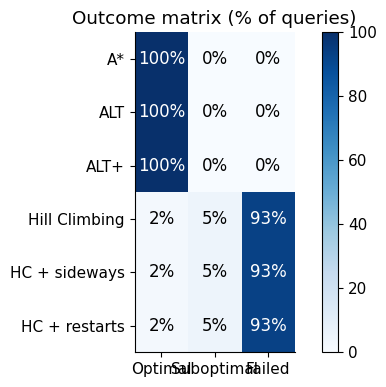

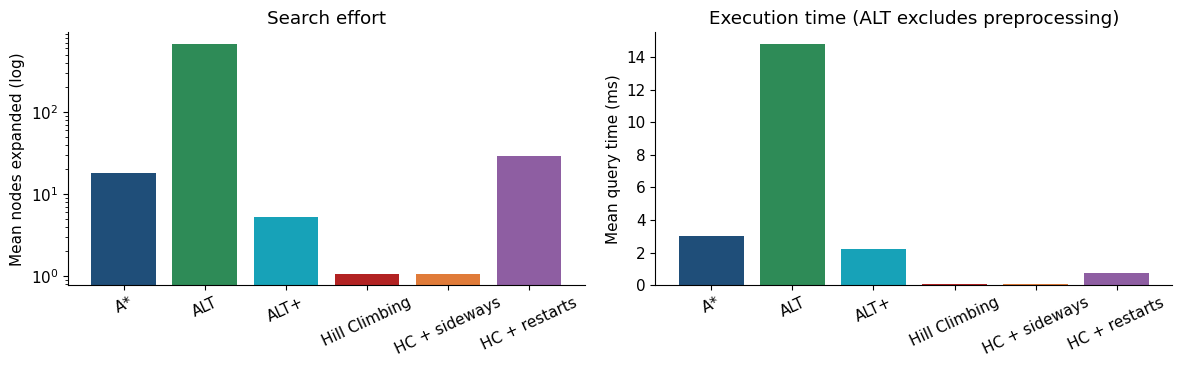

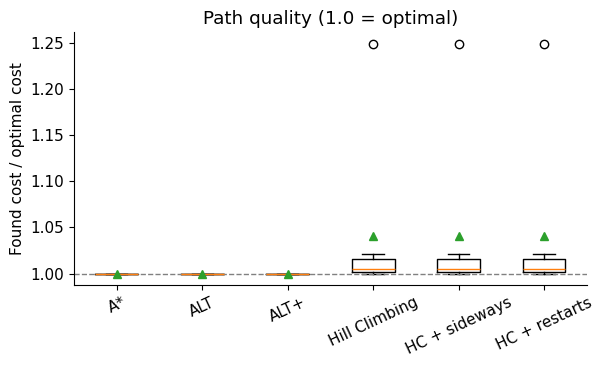

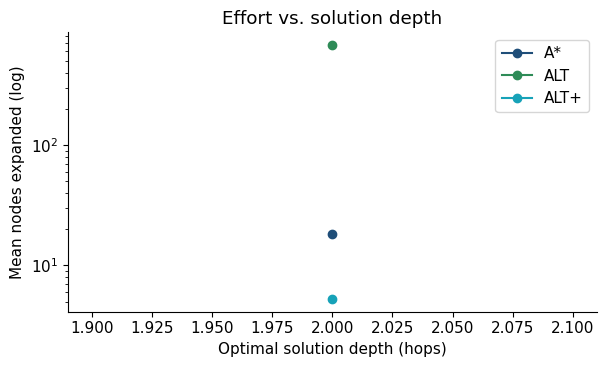

In [ ]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
COL = {"A*": "#1f4e79", "ALT": "#2e8b57", "ALT+": "#17a2b8", "Hill Climbing": "#b22222", "HC + sideways": "#e07b39", "HC + restarts": "#8e5ea2"}

# (a) outcome matrix
om = (pd.crosstab(all_res.algo, all_res.outcome, normalize="index") * 100).reindex(index=ORDER, columns=["Optimal", "Suboptimal", "Failed"]).fillna(0)
fig, ax = plt.subplots(figsize=(6.2, 4.0))
im = ax.imshow(om.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(3)); ax.set_xticklabels(om.columns); ax.set_yticks(range(len(om))); ax.set_yticklabels(om.index)
for i in range(om.shape[0]):
    for j in range(om.shape[1]):
        ax.text(j, i, f"{om.values[i, j]:.0f}%", ha="center", va="center", color="white" if om.values[i, j] > 55 else "black", fontsize=12)
ax.set_title("Outcome matrix (% of queries)"); plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_outcome_matrix.png", dpi=300); plt.show()

# (b) nodes expanded + time
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
m = all_res.groupby("algo").expanded.mean().loc[ORDER]
axs[0].bar(m.index, m.values, color=[COL[a] for a in m.index]); axs[0].set_yscale("log"); axs[0].set_ylabel("Mean nodes expanded (log)")
axs[0].set_title("Search effort"); axs[0].tick_params(axis="x", rotation=25)
tm = all_res.groupby("algo").time_ms.mean().loc[ORDER]
axs[1].bar(tm.index, tm.values, color=[COL[a] for a in tm.index]); axs[1].set_ylabel("Mean query time (ms)")
axs[1].set_title("Execution time (ALT excludes preprocessing)"); axs[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_effort_time.png", dpi=300); plt.show()

# (c) path quality of the hill-climbing variants (only queries where they succeeded)
fig, ax = plt.subplots(figsize=(6.2, 3.8))
data = [all_res[(all_res.algo == a) & all_res.found].cost_ratio.dropna().values for a in ORDER]
ax.boxplot([d if len(d) else [np.nan] for d in data], showmeans=True); ax.set_xticks(range(1, len(ORDER)+1)); ax.set_xticklabels(ORDER)
ax.axhline(1.0, ls="--", c="gray", lw=1); ax.set_ylabel("Found cost / optimal cost"); ax.set_title("Path quality (1.0 = optimal)")
ax.tick_params(axis="x", rotation=25); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_cost_ratio.png", dpi=300); plt.show()

# (d) effort vs. solution depth
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for a in ["A*", "ALT", "ALT+"]:
    d = all_res[all_res.algo == a].groupby("opt_depth").expanded.mean()
    ax.plot(d.index, d.values, marker="o", label=a, color=COL[a])
ax.set_yscale("log"); ax.set_xlabel("Optimal solution depth (hops)"); ax.set_ylabel("Mean nodes expanded (log)")
ax.set_title("Effort vs. solution depth"); ax.legend(); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_effort_vs_depth.png", dpi=300); plt.show()

## 9. Statistical comparison and honest findings

Paired tests on the *same* queries tell you whether a difference is real or noise. The sentences below are generated from your actual numbers (direction included), so they are safe to paste into *Results* and *Discussion*.

In [ ]:
from scipy.stats import wilcoxon
def wp(a, b):
    try: return wilcoxon(a, b).pvalue
    except ValueError: return 1.0
ex = lambda r: r.sort_values("query").expanded.values
p_alt, p_altp = wp(ex(res_astar), ex(res_alt)), wp(ex(res_astar), ex(res_altmax))
S = summary
A, B, C = S.loc["A*"], S.loc["ALT"], S.loc["ALT+"]
print(f"Paired Wilcoxon (nodes expanded) A* vs ALT:  p = {p_alt:.3g}\nPaired Wilcoxon (nodes expanded) A* vs ALT+: p = {p_altp:.3g}")

def ratio_sentence(name, X, p):
    a_, x_ = A["Mean nodes expanded"], X["Mean nodes expanded"]
    r = a_ / max(x_, 1e-9)
    if r >= 1: eff = f"{name} expanded {r:.1f}$\\times$ fewer nodes than \\Astar{{}} on average ({name}: {x_:.1f}, \\Astar{{}}: {a_:.1f})"
    else:      eff = f"{name} did \\emph{{not}} reduce the search effort: it expanded {1/r:.1f}$\\times$ \\emph{{more}} nodes than \\Astar{{}} on average ({name}: {x_:.1f}, \\Astar{{}}: {a_:.1f})"
    g_ = A["Mean nodes generated"] / max(X["Mean nodes generated"], 1e-9)
    gen = f"it generated {max(g_,1/g_):.1f}$\\times$ {'fewer' if g_ >= 1 else 'more'} nodes"
    tr = A["Mean time (ms)"] / max(X["Mean time (ms)"], 1e-9)
    tim = f"and was {max(tr,1/tr):.1f}$\\times$ {'faster' if tr >= 1 else 'slower'} per query ({name}: {X['Mean time (ms)']:.2f}\\,ms, \\Astar{{}}: {A['Mean time (ms)']:.2f}\\,ms; preprocessing excluded)"
    sig = "statistically significant" if p < 0.05 else "not statistically significant"
    ps = "<0.001" if p < 0.001 else f"={p:.3f}"
    return f"{eff}; {gen} {tim}. The difference in expansions is {sig} (paired Wilcoxon test, $p{ps}$)."

pre_ms = H_alt.preprocess_s * 1000
dt = A["Mean time (ms)"] - C["Mean time (ms)"]
breakeven = f"{pre_ms/dt:,.0f}" if dt > 1e-9 else "never (ALT+ was not faster per query)"
find_alt, find_altp = ratio_sentence("ALT", B, p_alt), ratio_sentence("ALT+", C, p_altp)
find_hc = (f"Steepest-ascent Hill Climbing reached the goal in {S.loc['Hill Climbing','Success rate (%)']:.0f}\\% of queries "
           f"(optimal in {S.loc['Hill Climbing','Optimal paths (%)']:.0f}\\%); with sideways moves the success rate was {S.loc['HC + sideways','Success rate (%)']:.0f}\\%, "
           f"and with random restarts {S.loc['HC + restarts','Success rate (%)']:.0f}\\% (optimal in {S.loc['HC + restarts','Optimal paths (%)']:.0f}\\%).")
print("\n---- Findings ----")
for k, v in [("ALT", find_alt), ("ALT+", find_altp), ("Hill climbing", find_hc)]: print(f"* {k}: {v}")
print(f"* ALT+ preprocessing ({H_alt.preprocess_s:.2f} s) pays off after: {breakeven} queries")
print(f"* Mean optimal solution depth: {A['Mean path depth (hops)']:.2f} hops")
if USING_SYNTHETIC: print("\n!! These numbers come from the SYNTHETIC stand-in graph. Re-run with the real dataset before using them.")

Paired Wilcoxon (nodes expanded) A* vs ALT:  p = 1.13e-11
Paired Wilcoxon (nodes expanded) A* vs ALT+: p = 3.81e-18

---- Findings ----
* ALT: ALT did \emph{not} reduce the search effort: it expanded 37.5$\times$ \emph{more} nodes than \Astar{} on average (ALT: 678.4, \Astar{}: 18.1); it generated 1.0$\times$ fewer nodes and was 4.9$\times$ slower per query (ALT: 14.79\,ms, \Astar{}: 3.03\,ms; preprocessing excluded). The difference in expansions is statistically significant (paired Wilcoxon test, $p<0.001$).
* ALT+: ALT+ expanded 3.4$\times$ fewer nodes than \Astar{} on average (ALT+: 5.2, \Astar{}: 18.1); it generated 1.5$\times$ fewer nodes and was 1.4$\times$ faster per query (ALT+: 2.22\,ms, \Astar{}: 3.03\,ms; preprocessing excluded). The difference in expansions is statistically significant (paired Wilcoxon test, $p<0.001$).
* Hill climbing: Steepest-ascent Hill Climbing reached the goal in 7\% of queries (optimal in 2\%); with sideways moves the success rate was 7\%, and with r

## 9a. Accuracy, data-processing and run-time report

**Accuracy score.** Search algorithms have no train/test split, so the equivalent of *accuracy* is the share of queries answered **correctly**, i.e. with an **optimal** path (cost equal to the ground-truth Dijkstra cost). We also report the **success rate** (goal reached at all) and a 95% **Wilson confidence interval** for the accuracy.

Below you get three tables (saved as CSV) and a run-time chart:
1. accuracy per algorithm, 2. data-processing summary, 3. time taken by every stage and by every algorithm.

=== ACCURACY (optimal-path rate) ===


,Queries,Accuracy = optimal paths (%),95% CI low,95% CI high,Success rate (%),Suboptimal (%),Failed (%),Mean cost ratio (found)
Algorithm,,,,,,,,
A*,100,100.0,96.30,100.0,100.0,0.0,0.0,1.00
ALT,100,100.0,96.30,100.0,100.0,0.0,0.0,1.00
ALT+,100,100.0,96.30,100.0,100.0,0.0,0.0,1.00
Hill Climbing,100,2.0,0.55,7.0,7.0,5.0,93.0,1.04
HC + sideways,100,2.0,0.55,7.0,7.0,5.0,93.0,1.04
HC + restarts,100,2.0,0.55,7.0,7.0,5.0,93.0,1.04



=== DATA PROCESSING SUMMARY ===


,Value
Edge files read,3
Rows read per file (limit),1500000
Edge rows loaded (total),4500000
Self-loops dropped,0
Duplicate (bidirectional) entries dropped,3610422
Node types,"user, package, cell, app"
Distinct nodes before component filter,170380
Undirected edges before component filter,2694789
Nodes in largest connected component,8519
Edges in largest connected component,134736



=== TIME TAKEN ===


,Seconds,Share (%)
1. Download + read edge files,605.295,98.099
"2. Build graph (IDs, costs, CSR, largest component)",3.345,0.542
3. Ground truth (Dijkstra for every query),0.271,0.044
4. ALT landmark preprocessing,0.059,0.010
5. Run all queries: A*,0.347,0.056
5. Run all queries: ALT,1.516,0.246
5. Run all queries: ALT+,0.247,0.040
5. Run all queries: HC + restarts,0.082,0.013
5. Run all queries: HC + sideways,0.011,0.002
5. Run all queries: Hill Climbing,0.008,0.001



=== TIME PER QUERY ===


,mean ms/query,median ms/query,max ms/query
algo,,,
A*,3.032,3.046,5.172
ALT,14.795,7.280,57.528
ALT+,2.216,2.136,4.845
Hill Climbing,0.053,0.024,0.758
HC + sideways,0.059,0.031,0.833
HC + restarts,0.765,0.780,0.990


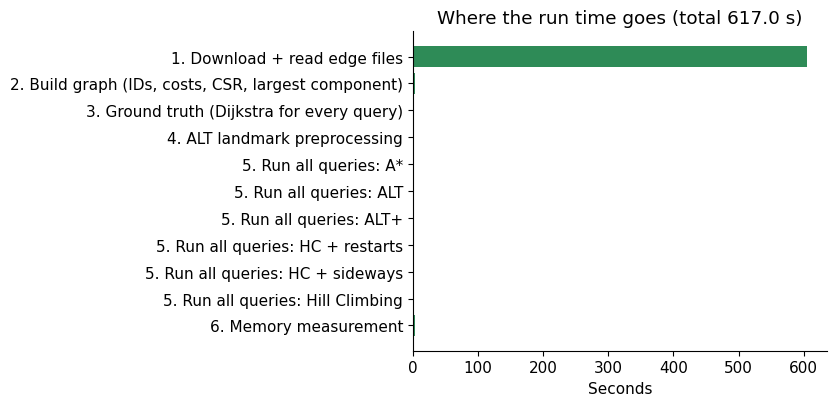

In [ ]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z*z/n; c = p + z*z/(2*n); h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return ((c - h)/d*100, (c + h)/d*100)

rows = []
for a in ORDER:
    d = all_res[all_res.algo == a]; n_ = len(d); k_ = int((d.outcome == "Optimal").sum()); lo, hi = wilson(k_, n_)
    rows.append({"Algorithm": a, "Queries": n_, "Accuracy = optimal paths (%)": 100*k_/n_, "95% CI low": lo, "95% CI high": hi,
                 "Success rate (%)": 100*d.found.mean(), "Suboptimal (%)": 100*(d.outcome == "Suboptimal").mean(),
                 "Failed (%)": 100*(d.outcome == "Failed").mean(), "Mean cost ratio (found)": d[d.found].cost_ratio.mean()})
accuracy_table = pd.DataFrame(rows).set_index("Algorithm").round(2)
accuracy_table.to_csv(f"{OUT_DIR}/table2_accuracy.csv")
print("=== ACCURACY (optimal-path rate) ==="); display(accuracy_table)

st = g.stats
dp = pd.Series({
    "Edge files read": len(files), "Rows read per file (limit)": "all" if MAX_ROWS_PER_EDGE_FILE is None else MAX_ROWS_PER_EDGE_FILE,
    "Edge rows loaded (total)": st["rows_read"], "Self-loops dropped": st["self_loops_dropped"],
    "Duplicate (bidirectional) entries dropped": st["duplicate_edges_dropped"], "Node types": ", ".join(g.type_names),
    "Distinct nodes before component filter": st["nodes_before_component"], "Undirected edges before component filter": st["edges_before_component"],
    "Nodes in largest connected component": st["nodes_final"], "Edges in largest connected component": st["edges_final"],
    "Mean / max degree": f"{g.degree.mean():.1f} / {g.degree.max():,}", "Edge cost range": f"[{g.data.min():.3f}, {g.data.max():.3f}]",
    "Queries (type, count)": f"{QUERY_TYPE}, {len(queries)}", "Random seed": SEED}).astype(str).to_frame("Value")
dp.to_csv(f"{OUT_DIR}/table3_data_processing.csv")
print("\n=== DATA PROCESSING SUMMARY ==="); display(dp)

total_s = time.perf_counter() - RUN_START
tt = pd.DataFrame({"Seconds": pd.Series(STAGE)}).sort_index()
tt.loc["TOTAL notebook run time (up to this point)"] = total_s
tt["Share (%)"] = 100 * tt["Seconds"] / total_s; tt = tt.round(3)
tt.to_csv(f"{OUT_DIR}/table4_runtime.csv")
print("\n=== TIME TAKEN ==="); display(tt)
per_q = all_res.groupby("algo").time_ms.agg(["mean", "median", "max"]).loc[ORDER].round(3).rename(columns={"mean": "mean ms/query", "median": "median ms/query", "max": "max ms/query"})
print("\n=== TIME PER QUERY ==="); display(per_q)

fig, ax = plt.subplots(figsize=(8.5, 4.2)); items = tt.drop(index=[i for i in tt.index if i.startswith("TOTAL")])["Seconds"]
ax.barh(items.index[::-1], items.values[::-1], color="#2e8b57"); ax.set_xlabel("Seconds"); ax.set_title(f"Where the run time goes (total {total_s:.1f} s)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_runtime_stages.png", dpi=300); plt.show()

In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=accuracy_table)

https://docs.google.com/spreadsheets/d/1djj3ZV5MlBindnpCGaK7RP2Fhu4PRpCYPWDUuNrlxJE/edit#gid=0


## 9b. Export every number to LaTeX

This writes `results_macros.tex`. Upload it to your Overleaf project next to `main.tex`; the report then fills in all numbers and result sentences automatically, so nothing is copied by hand.

In [ ]:
NAMES = {"A*": "Astar", "ALT": "Alt", "ALT+": "Altp", "Hill Climbing": "Hc", "HC + sideways": "Hcs", "HC + restarts": "Hcr"}
METRICS = {"Success rate (%)": ("Succ", 1), "Optimal paths (%)": ("Opt", 1), "Mean cost ratio (found)": ("Ratio", 3),
           "Mean path cost (found)": ("Cost", 3), "Mean path depth (hops)": ("Depth", 2), "Mean nodes expanded": ("Exp", 1),
           "Median nodes expanded": ("ExpMed", 1), "Mean nodes generated": ("Gen", 0), "Mean max frontier": ("Front", 0),
           "Mean time (ms)": ("Time", 2), "Peak memory/query (MB)": ("Mem", 3)}
def fmt(v, dec): return "--" if (v is None or (isinstance(v, float) and not np.isfinite(v))) else f"{v:,.{dec}f}"
lines = ["% AUTO-GENERATED by the Colab notebook. Do not edit by hand."]
def mac(name, val): lines.append("\\newcommand{\\res%s}{%s}" % (name, val))
for algo, key in NAMES.items():
    for col, (m, dec) in METRICS.items(): mac(key + m, fmt(float(summary.loc[algo, col]), dec))
for tn in ["user", "package", "app", "cell"]:
    mac("N" + tn.capitalize(), f"{comp.get(tn, 0):,}")
mac("NodesAll", f"{run_:,}"); mac("Nodes", f"{g.n:,}"); mac("Edges", f"{g.m:,}")
mac("MeanDeg", f"{g.degree.mean():.1f}"); mac("MaxDeg", f"{g.degree.max():,}")
mac("CostMin", f"{g.data.min():.3f}"); mac("CostMax", f"{g.data.max():.3f}")
mac("NQ", str(len(queries))); mac("Rows", "all" if MAX_ROWS_PER_EDGE_FILE is None else f"{MAX_ROWS_PER_EDGE_FILE:,}")
mac("K", str(N_LANDMARKS)); mac("Pre", f"{H_alt.preprocess_s:.2f}"); mac("TableMB", f"{H_alt.table_mb:.2f}")
mac("Sideways", str(HC_SIDEWAYS)); mac("Restarts", str(HC_RESTARTS)); mac("QType", str(QUERY_TYPE))
mac("OptCostMean", f"{truth.true_cost.mean():.3f}")
mac("PAlt", "<0.001" if p_alt < 0.001 else f"{p_alt:.3f}"); mac("PAltp", "<0.001" if p_altp < 0.001 else f"{p_altp:.3f}"); mac("Breakeven", breakeven)
mac("FindAlt", find_alt); mac("FindAltp", find_altp); mac("FindHc", find_hc)
mac("TotalTime", f"{total_s:.1f}"); mac("LoadTime", f"{STAGE['1. Download + read edge files']:.1f}")
mac("Synthetic", "1" if USING_SYNTHETIC else "0")
open(f"{OUT_DIR}/results_macros.tex", "w").write("\n".join(lines) + "\n")
print(f"Wrote {OUT_DIR}/results_macros.tex ({len(lines)-1} macros)")

Wrote /content/results/results_macros.tex (95 macros)


## 10. Visualisations for the report (Design and Results sections)

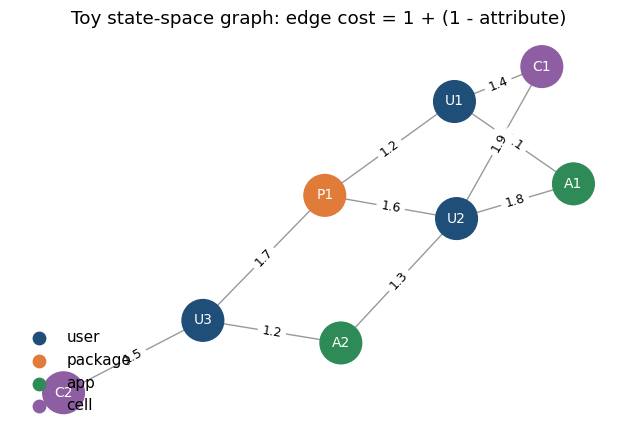

In [ ]:
# (a) Toy state-space diagram: shows the problem representation (node types, edge costs)
T = nx.Graph()
types = {"U1": "user", "U2": "user", "U3": "user", "P1": "package", "A1": "app", "A2": "app", "C1": "cell", "C2": "cell"}
edges = [("U1","P1",1.2),("U2","P1",1.6),("U1","A1",1.1),("U2","A1",1.8),("U2","A2",1.3),("U3","A2",1.2),("U3","C2",1.5),("U1","C1",1.4),("U2","C1",1.9),("U3","P1",1.7)]
for u, v, c in edges: T.add_edge(u, v, w=c)
colors = {"user": "#1f4e79", "package": "#e07b39", "app": "#2e8b57", "cell": "#8e5ea2"}
pos = nx.spring_layout(T, seed=3)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
nx.draw_networkx_edges(T, pos, ax=ax, edge_color="#999")
nx.draw_networkx_nodes(T, pos, ax=ax, node_color=[colors[types[n]] for n in T], node_size=900)
nx.draw_networkx_labels(T, pos, ax=ax, font_color="white", font_size=10)
nx.draw_networkx_edge_labels(T, pos, {(u, v): c for u, v, c in edges}, ax=ax, font_size=9)
for tname, c in colors.items(): ax.scatter([], [], c=c, label=tname, s=80)
ax.legend(loc="lower left", frameon=False); ax.set_title("Toy state-space graph: edge cost = 1 + (1 - attribute)"); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_state_space_toy.png", dpi=300); plt.show()

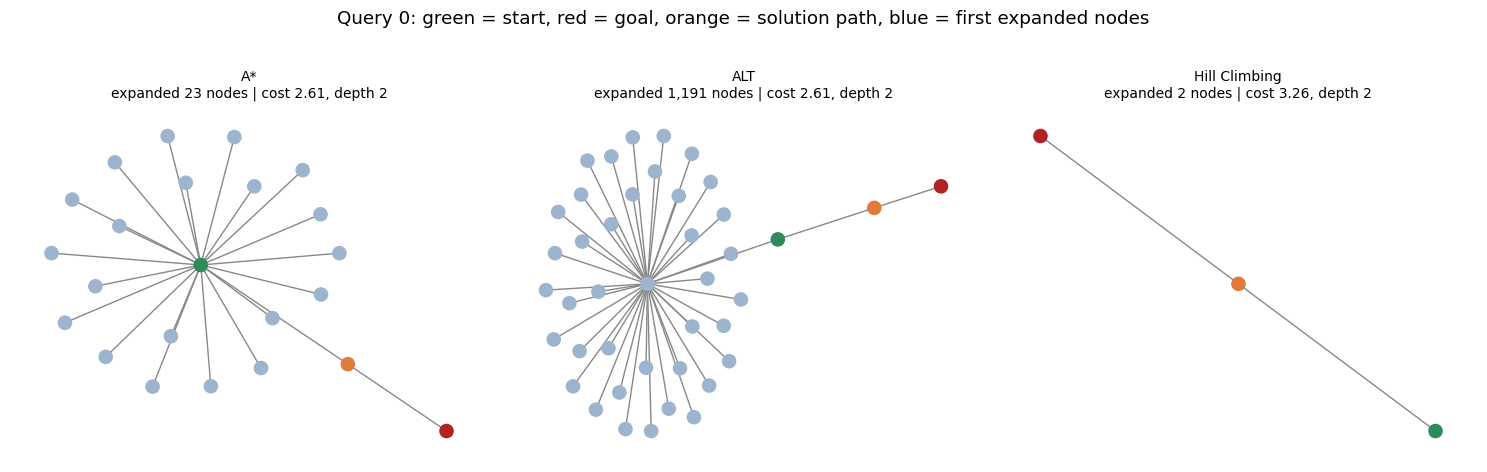

In [ ]:
# (b) Search tree of the first expanded nodes + solution path for one query, for each algorithm
cand = all_res[(all_res.algo == "A*") & (all_res.opt_depth >= 4)]
qi = int(cand.iloc[0].query) if len(cand) else 0
s, t = queries[qi]
runs = {"A*": astar(g, s, t, H_weak, trace=True), "ALT": astar(g, s, t, H_alt, trace=True),
        "Hill Climbing": hill_climb(g, s, t, H_alt, trace=True)}

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (name, r) in zip(axs, runs.items()):
    M = 40; first = set(r["order"][:M]) | {s}
    G_ = nx.Graph(); G_.add_nodes_from(first)
    G_.add_edges_from([(p, v) for p, v in r["tree_edges"] if p in first and v in first])
    on_path = set(r["path"]) if r["found"] else set()
    for p, v in zip(r["path"][:-1], r["path"][1:]):
        G_.add_edge(p, v); first |= {p, v}
    cols = ["#2e8b57" if n_ == s else "#b22222" if n_ == t else "#e07b39" if n_ in on_path else "#9db4cf" for n_ in G_]
    nx.draw(G_, nx.spring_layout(G_, seed=1), ax=ax, node_color=cols, node_size=90, edge_color="#888", width=1)
    status = f"cost {r['cost']:.2f}, depth {r['depth']:.0f}" if r["found"] else "FAILED (stuck)"
    ax.set_title(f"{name}\nexpanded {r['expanded']:,} nodes | {status}", fontsize=10)
fig.suptitle(f"Query {qi}: green = start, red = goal, orange = solution path, blue = first expanded nodes", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_search_trees.png", dpi=300, bbox_inches="tight"); plt.show()

## 11. Package everything for download

In [ ]:
import shutil
try:   # export all executed cells as one .py file for the report appendix
    hist = [c for c in get_ipython().user_ns["In"][1:-1] if c.strip() and not c.lstrip().startswith(("%", "!"))]
    open(f"{OUT_DIR}/notebook_code.py", "w").write("\n\n".join(hist))
except Exception as e: print("(code export skipped:", e, ")")
shutil.make_archive("/content/results_bundle", "zip", OUT_DIR)
print("Files saved:", sorted(os.listdir(OUT_DIR)))
print(f"TOTAL time taken by the whole notebook: {time.perf_counter() - RUN_START:.1f} s")
try:
    from google.colab import files; files.download("/content/results_bundle.zip")
except Exception: print("(Not running in Colab: bundle is at /content/results_bundle.zip)")

Files saved: ['all_query_results.csv', 'fig_cost_ratio.png', 'fig_effort_time.png', 'fig_effort_vs_depth.png', 'fig_outcome_matrix.png', 'fig_runtime_stages.png', 'fig_search_trees.png', 'fig_state_space_toy.png', 'notebook_code.py', 'results_macros.tex', 'table1_summary.csv', 'table2_accuracy.csv', 'table3_data_processing.csv', 'table4_runtime.csv']
TOTAL time taken by the whole notebook: 618.4 s


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>